## 1. Load Cleaned Data

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('../Dataset/telco_churn_cleaned.csv')
df.shape

(7043, 30)

## 2. Drop Leakage & Non-Predictive Columns
`Churn Score` and `CLTV` are IBM-derived scores tied to the churn outcome — using 
them would be data leakage. `Churn Label` and `Churn Reason` directly describe the 
outcome. `CustomerID` is just an identifier (we'll keep it aside separately for 
Phase 6 scoring, not as a model input).

In [3]:
customer_ids = df['CustomerID']  # keep aside for later (Phase 6 risk list)

drop_cols = ['CustomerID', 'Churn Score', 'CLTV', 'Churn Reason', 'Churn Label',
             'Zip Code', 'Latitude', 'Longitude', 'City', 'State']

df_model = df.drop(columns=drop_cols)
df_model.shape

(7043, 20)

## 3. Encode Categorical Variables
One-hot encode all text/categorical columns so the model can use them numerically.
`drop_first=True` avoids redundant columns (e.g. Gender_Male alone implies Female).

In [4]:
y = df_model['Churn Value']
X = df_model.drop(columns=['Churn Value'])

X_encoded = pd.get_dummies(X, drop_first=True)
X_encoded.shape

(7043, 30)

## 4. Train/Test Split
Hold out 20% of data purely for evaluation — the model never sees this during training.
`stratify=y` ensures both sets keep the same ~26.5% churn ratio.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())  

(5634, 30) (1409, 30)
0.2653532126375577 0.2654364797728886


## 5. Baseline Model — Logistic Regression
Scale numeric features first (Logistic Regression is sensitive to feature scale, 
unlike tree-based models), then train with `class_weight='balanced'` to handle 
the churn imbalance.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Identify numeric columns that need scaling
numeric_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

log_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_model.fit(X_train_scaled, y_train)

y_pred_log = log_model.predict(X_test_scaled)
display(y_pred_log)

array([0, 1, 0, ..., 0, 0, 0], shape=(1409,))

## 6. Evaluate Logistic Regression
Accuracy alone is misleading on imbalanced data — precision, recall, F1, and 
ROC-AUC give a truer picture.

In [7]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, y_pred_log))
print("ROC-AUC:", roc_auc_score(y_test, log_model.predict_proba(X_test_scaled)[:, 1]))

              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409

ROC-AUC: 0.8488697718876748


## 7. Stronger Model — Random Forest

In [8]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200, class_weight='balanced', random_state=42, max_depth=10
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

           0       0.89      0.78      0.83      1035
           1       0.55      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

ROC-AUC: 0.8517902813299233


## 8. Feature Importance (Random Forest)
Which inputs actually drove the model's predictions — should align with EDA/SQL findings.

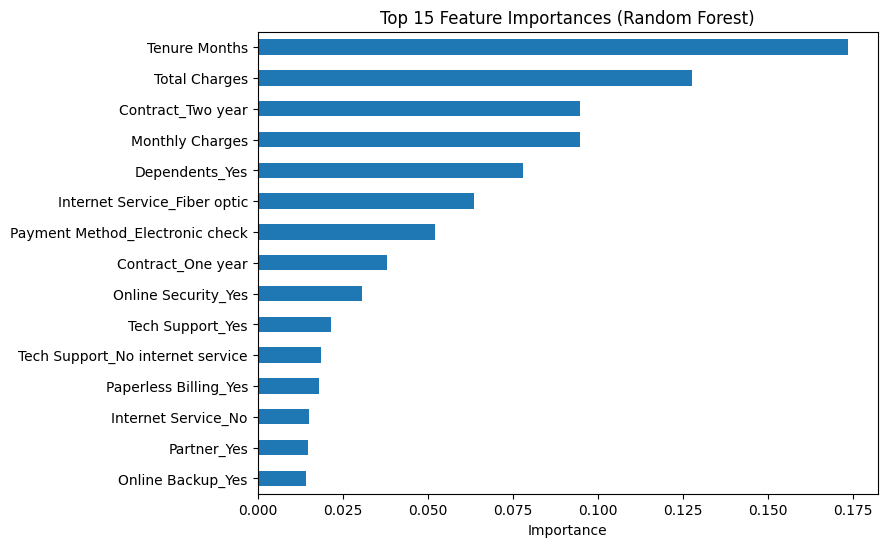

In [9]:
import matplotlib.pyplot as plt

importances = pd.Series(rf_model.feature_importances_, index=X_encoded.columns)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8,6))
top15.sort_values().plot(kind='barh')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.show()

## 9. Summary — Model Comparison & Selection

Two models were trained to predict customer churn: **Logistic Regression** as the baseline model and **Random Forest** as the tree-based model.

| Metric            | Logistic Regression | Random Forest |
| ----------------- | ------------------: | ------------: |
| ROC-AUC           |              0.8489 |    **0.8518** |
| Accuracy          |                0.74 |      **0.77** |
| Recall (Churn)    |            **0.78** |          0.74 |
| Precision (Churn) |                0.51 |      **0.55** |
| F1-score (Churn)  |                0.62 |      **0.63** |

Both models perform similarly in terms of ROC-AUC, with a difference of only **0.0029**. Logistic Regression identifies more actual churners, with **78% recall**, while Random Forest achieves higher **accuracy, precision, and F1-score**.

**Model selected: Random Forest.** Based on the evaluated test-set metrics, Random Forest achieved the highest ROC-AUC (**0.8518**) and F1-score (**0.63**), along with higher accuracy and precision than Logistic Regression. Therefore, Random Forest was selected for generating customer churn probability scores.

The important features identified by the Random Forest model, including **Tenure Months, Total Charges, Contract, Monthly Charges, Dependents, Internet Service, and Payment Method**, are broadly consistent with patterns identified earlier through EDA and SQL analysis. This provides consistency across the different analytical stages of the project.

The selected Random Forest model is then used to generate **customer-level churn probabilities**, identify active high-risk customers, and create a prioritized retention list for the next stage of the project.


## 10. Retrain Final Model on Full Data for Production Scoring
The Random Forest was evaluated on the held-out 20% test set (fair comparison). 
Now that it's selected as the final model, retrain it on 100% of the data before 
generating real-world risk scores — standard practice once model selection is done, 
so every customer gets a prediction from a model that had access to the fullest, 
most representative training signal.

In [10]:
# Retrain Random Forest on the FULL dataset for final production scoring
# (rf_model was only trained on X_train/80% for fair evaluation purposes)
final_model = RandomForestClassifier(
    n_estimators=200, class_weight='balanced', random_state=42, max_depth=10
)
final_model.fit(X_encoded, y)

# Get churn probability for every customer using the full encoded dataset
df['Churn_Probability'] = final_model.predict_proba(X_encoded)[:, 1]

# Build a risk-ranked view combining probability with value (CLTV)
risk_list = df[['CustomerID', 'Churn Label', 'Churn_Probability', 'CLTV', 
                 'Monthly Charges', 'Tenure Months', 'Contract']].copy()

# Focus on currently active customers only (can't retain someone who already left)
risk_list = risk_list[risk_list['Churn Label'] == 'No']

# Sort by churn probability first, then by CLTV (prioritize high-value + high-risk)
risk_list = risk_list.sort_values(by=['Churn_Probability', 'CLTV'], ascending=[False, False])

risk_list.head(20)

,CustomerID,Churn Label,Churn_Probability,CLTV,Monthly Charges,Tenure Months,Contract
2215,1452-VOQCH,No,0.932133,4120,75.10,1,Month-to-month
2676,7439-DKZTW,No,0.930597,3154,80.55,1,Month-to-month
5657,7577-SWIFR,No,0.921050,5579,89.25,1,Month-to-month
4030,5542-TBBWB,No,0.919586,3358,69.90,1,Month-to-month
4329,1640-PLFMP,No,0.913881,4063,70.25,1,Month-to-month
4551,3878-AVSOQ,No,0.913682,5033,71.25,1,Month-to-month
5177,7465-ZZRVX,No,0.912744,2722,70.35,1,Month-to-month
6353,9605-WGJVW,No,0.911865,2422,70.20,1,Month-to-month
4198,5150-ITWWB,No,0.906744,4496,94.85,3,Month-to-month
3662,9603-OAIHC,No,0.905242,2469,70.05,1,Month-to-month


## 11. Export High-Risk Customer List
Save the top at-risk customers to a CSV — this becomes the actual deliverable 
a retention team would use, and also feeds into the Power BI dashboard later.

In [25]:
top_risk_customers = risk_list.head(100)
top_risk_customers.to_csv('C:/Users/Himanshu/Desktop/Customer churn/Dataset/top_risk_customers.csv', index=False)

print(f"Exported {len(top_risk_customers)} high-risk customers")
top_risk_customers.head(10)

Exported 100 high-risk customers


,CustomerID,Churn Label,Churn_Probability,CLTV,Monthly Charges,Tenure Months,Contract
2215,1452-VOQCH,No,0.932133,4120,75.10,1,Month-to-month
2676,7439-DKZTW,No,0.930597,3154,80.55,1,Month-to-month
5657,7577-SWIFR,No,0.921050,5579,89.25,1,Month-to-month
4030,5542-TBBWB,No,0.919586,3358,69.90,1,Month-to-month
4329,1640-PLFMP,No,0.913881,4063,70.25,1,Month-to-month
4551,3878-AVSOQ,No,0.913682,5033,71.25,1,Month-to-month
5177,7465-ZZRVX,No,0.912744,2722,70.35,1,Month-to-month
6353,9605-WGJVW,No,0.911865,2422,70.20,1,Month-to-month
4198,5150-ITWWB,No,0.906744,4496,94.85,3,Month-to-month
3662,9603-OAIHC,No,0.905242,2469,70.05,1,Month-to-month


## Export Full Risk-Scored Customer List
Save the complete risk-scored list of all active customers (with churn probability 
and risk tier) for use in the Power BI dashboard. Unlike the top 100 priority list, 
this file supports tier-level KPIs, charts, and filtering.

In [11]:
risk_list.to_csv('C:/Users/Himanshu/Desktop/Customer churn/Dataset/risk_scored_customers.csv', index=False)
print(f"Exported {len(risk_list)} active customers")

Exported 5174 active customers


## 12. Risk Segment Summary
Bucket all active customers into risk tiers (Low/Medium/High) based on predicted 
probability, to give a quick overview of how many customers fall into each category.

In [13]:
def risk_tier(prob):
    if prob >= 0.6:
        return 'High Risk'
    elif prob >= 0.3:
        return 'Medium Risk'
    else:
        return 'Low Risk'

risk_list['Risk Tier'] = risk_list['Churn_Probability'].apply(risk_tier)

tier_summary = risk_list.groupby('Risk Tier').agg(
    customer_count=('CustomerID', 'count'),
    total_monthly_revenue=('Monthly Charges', 'sum'),
    avg_cltv=('CLTV', 'mean')
).round(2)

tier_summary

,customer_count,total_monthly_revenue,avg_cltv
Risk Tier,,,
High Risk,610,46269.85,4039.30
Low Risk,3498,193738.45,4607.85
Medium Risk,1066,76977.45,4365.65


## 13. Summary — Phase 6: High-Risk Customer Identification

The final Random Forest model (retrained on the full dataset for production 
scoring) was used to assign a churn probability to every active customer. 
Customers were segmented into three risk tiers:

| Risk Tier | Customers | Monthly Revenue | Avg CLTV |
|---|---|---|---|
| High Risk | 610 | 46,269.85 USD | 4,039.30 |
| Medium Risk | 1,066 | 76,977.45 USD | 4,365.65 |
| Low Risk | 3,498 | 193,738.45 USD | 4,607.85 |

Combined, High and Medium Risk customers total **1,676 active customers**, 
representing **123,247.30 USD/month** in revenue — roughly **39% of total 
active-customer revenue** — sitting in a meaningful churn risk zone.

Notably, High Risk customers have the lowest average CLTV of the three tiers, 
indicating churn risk and customer value are not perfectly aligned: higher-risk 
customers tend to be newer and have not yet accumulated high lifetime value. 
This reinforces combining churn probability with CLTV (rather than risk tier 
alone) when prioritizing retention spend — a pattern also surfaced earlier in 
the SQL high-value-at-risk analysis (Phase 3, Query 2).

A prioritized list of the top 100 highest-risk, highest-value active customers 
was exported to `top_risk_customers.csv` for use by the retention team and 
for the Power BI dashboard.